# cell 1


In [1]:
import os
import random
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset

import torchvision
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
    auc,
)
from sklearn.preprocessing import label_binarize

torch.manual_seed(0)
np.random.seed(0)
random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# cell 2

In [2]:
DATASET_SLUG = "ahsiulkarim/eye-disease-image-dataset"
DATA_DIR = Path("/kaggle/input/datasets/ahsiulkarim/eye-disease-image-dataset/Eye Disease Image Dataset/Original Dataset/Original Dataset")

EXPECTED_CLASSES = [
    "Central Serous Chorioretinopathy (Color Fundus)",
    "Diabetic Retinopathy",
    "Disc Edema",
    "Glaucoma",
    "Healthy",
    "Macular Scar",
    "Myopia",
    "Pterygium",
    "Retinal Detachment",
    "Retinitis Pigmentosa",
]

IMG_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2
CNN_EPOCHS = 30
GNN_EPOCHS = 30
CV_EPOCHS = 8
CV_BATCH_SIZE = 256
CV_EARLY_STOPPING_PATIENCE = 2
LEARNING_RATE = 1e-4
GNN_LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-5
EARLY_STOPPING_PATIENCE = 5
CNN_EARLY_STOPPING_PATIENCE = 3
VIG_WEIGHT_DECAY = 1e-4
VIG_EARLY_STOPPING_PATIENCE = 3
CNN_MIN_DELTA = 1e-4
MIN_DELTA = 1e-4
BEST_MODEL_DIR = Path("best_gnn_models")
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)
BEST_CNN_MODEL_PATH = BEST_MODEL_DIR / "ResNet50_CNN_best.pt"

# Optional fast smoke-test switch. Keep this as None for the full final experiment.
MAX_IMAGES_PER_CLASS = None


def download_dataset_if_needed(data_dir=DATA_DIR):
    '''Download the Kaggle dataset if it is not already present.'''
    if data_dir.exists() and any(data_dir.rglob("*")):
        print("Dataset folder already exists:", data_dir.resolve())
        return data_dir

    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError(
            "Install kagglehub first, or download the dataset manually into DATA_DIR. "
            "Example: %pip install kagglehub"
        ) from exc

    downloaded_path = Path(kagglehub.dataset_download(DATASET_SLUG))
    print("Downloaded to:", downloaded_path)
    return downloaded_path


image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def has_images(path):
    return any(p.suffix.lower() in image_extensions for p in path.rglob("*") if p.is_file())


def class_dir_score(path):
    children = [p for p in path.iterdir() if p.is_dir()]
    if len(children) < 2:
        return 0
    image_class_dirs = [p for p in children if has_images(p)]
    return len(image_class_dirs)


def find_imagefolder_root(start_path):
    '''Find the directory that ImageFolder should read.'''
    start_path = Path(start_path)

    # If a train/test split already exists, prefer the train folder for class discovery.
    for split_name in ["train", "Train", "training", "Training"]:
        split_path = start_path / split_name
        if split_path.exists() and class_dir_score(split_path) >= 2:
            return split_path

    candidates = [p for p in [start_path, *start_path.rglob("*")] if p.is_dir()]
    scored = [(class_dir_score(p), p) for p in candidates]
    scored = [(score, p) for score, p in scored if score >= 2]
    if not scored:
        raise FileNotFoundError(
            f"Could not find class folders below {start_path}. "
            "Please set DATA_DIR to the folder that contains the class subfolders."
        )
    scored.sort(key=lambda x: x[0], reverse=True)
    return scored[0][1]


raw_dataset_path = download_dataset_if_needed(DATA_DIR)
image_root = find_imagefolder_root(raw_dataset_path)
print("ImageFolder root:", image_root)

Dataset folder already exists: /kaggle/input/datasets/ahsiulkarim/eye-disease-image-dataset/Eye Disease Image Dataset/Original Dataset/Original Dataset
ImageFolder root: /kaggle/input/datasets/ahsiulkarim/eye-disease-image-dataset/Eye Disease Image Dataset/Original Dataset/Original Dataset


# cell 3

In [3]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

display_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

full_dataset_for_split = datasets.ImageFolder(image_root, transform=test_transform)
class_names = full_dataset_for_split.classes
num_classes = len(class_names)

print("Classes found by ImageFolder:")
for i, name in enumerate(class_names):
    print(f"{i:2d}: {name}")

if num_classes != 10:
    print(f"\nWarning: expected 10 classes, but ImageFolder found {num_classes}. Check image_root if this is not intended.")

targets = np.array([label for _, label in full_dataset_for_split.samples])
indices = np.arange(len(full_dataset_for_split))

if MAX_IMAGES_PER_CLASS is not None:
    kept = []
    for cls in np.unique(targets):
        cls_idx = indices[targets == cls]
        rng = np.random.default_rng(0)
        kept.extend(rng.choice(cls_idx, size=min(MAX_IMAGES_PER_CLASS, len(cls_idx)), replace=False).tolist())
    indices = np.array(sorted(kept))
    targets = targets[indices]

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=0,
    stratify=targets,
)

# Keep the original held-out test set untouched.
# The training portion is split again into train/validation so Early Stopping
# never uses the final test set to select the best GNN checkpoint.
train_targets = targets[np.isin(indices, train_idx)]
gnn_train_idx, val_idx = train_test_split(
    train_idx,
    test_size=0.20,
    random_state=0,
    stratify=targets[train_idx],
)

train_dataset = datasets.ImageFolder(image_root, transform=train_transform)
val_dataset = datasets.ImageFolder(image_root, transform=test_transform)
test_dataset = datasets.ImageFolder(image_root, transform=test_transform)
display_dataset = datasets.ImageFolder(image_root, transform=display_transform)

train_subset = Subset(train_dataset, train_idx.tolist())
gnn_train_subset = Subset(train_dataset, gnn_train_idx.tolist())
val_subset = Subset(val_dataset, val_idx.tolist())
test_subset = Subset(test_dataset, test_idx.tolist())
display_subset = Subset(display_dataset, test_idx.tolist())

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
gnn_train_loader = DataLoader(gnn_train_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print("Images:", len(full_dataset_for_split))
print("CNN Train:", len(train_subset), "GNN Train:", len(gnn_train_subset), "Validation:", len(val_subset), "Test:", len(test_subset))

Classes found by ImageFolder:
 0: Central Serous Chorioretinopathy [Color Fundus]
 1: Diabetic Retinopathy
 2: Disc Edema
 3: Glaucoma
 4: Healthy
 5: Macular Scar
 6: Myopia
 7: Pterygium
 8: Retinal Detachment
 9: Retinitis Pigmentosa
Images: 5335
CNN Train: 4268 GNN Train: 3414 Validation: 854 Test: 1067


# cell 4


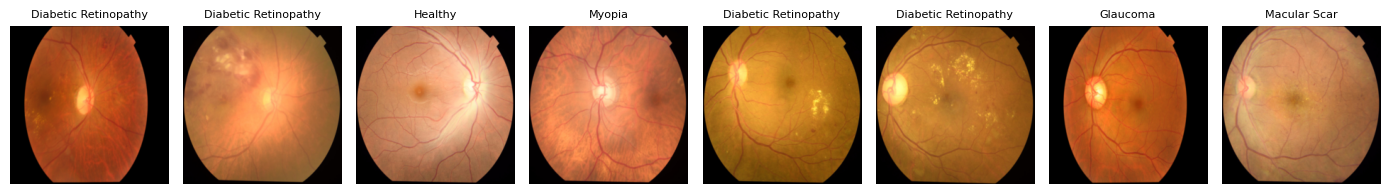

In [4]:
# Show a few images, like the sample notebook does after loading data.
fig, axes = plt.subplots(1, min(8, len(display_subset)), figsize=(14, 2.2))
if len(display_subset) == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    img, label = display_subset[i]
    ax.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    ax.set_title(class_names[label], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

# cell 5

49 nodes, 84 edges


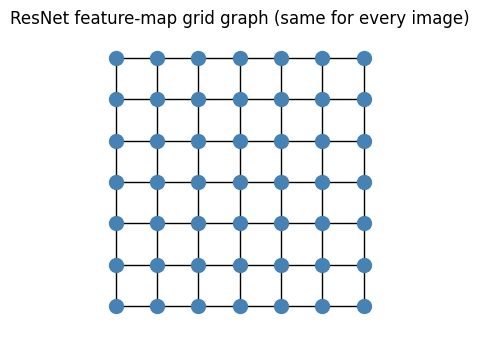

In [5]:
FEATURE_H, FEATURE_W = 7, 7
n_nodes = FEATURE_H * FEATURE_W


def node_id(r, c):
    return r * FEATURE_W + c


G = nx.Graph()
G.add_nodes_from(range(n_nodes))
for r in range(FEATURE_H):
    for c in range(FEATURE_W):
        if r + 1 < FEATURE_H:
            G.add_edge(node_id(r, c), node_id(r + 1, c))
        if c + 1 < FEATURE_W:
            G.add_edge(node_id(r, c), node_id(r, c + 1))

A = nx.to_numpy_array(G)
A_tilde = A + np.eye(n_nodes)                       # add self-loops
D_inv_sqrt = np.diag(1.0 / np.sqrt(A_tilde.sum(axis=1)))
A_hat = torch.tensor(D_inv_sqrt @ A_tilde @ D_inv_sqrt, dtype=torch.float32).to(device)

print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

pos = {node_id(r, c): (c, -r) for r in range(FEATURE_H) for c in range(FEATURE_W)}
plt.figure(figsize=(3, 3))
nx.draw(G, pos, node_size=100, node_color="steelblue")
plt.title("ResNet feature-map grid graph (same for every image)")
plt.show()

# cell 6

In [6]:
row_pos = np.array([r for r in range(FEATURE_H) for c in range(FEATURE_W)]) / FEATURE_H
col_pos = np.array([c for r in range(FEATURE_H) for c in range(FEATURE_W)]) / FEATURE_W
pos_features = torch.tensor(np.stack([row_pos, col_pos], axis=1), dtype=torch.float32)


def make_features(feature_maps):
    '''
    feature_maps: (n_images, channels, 7, 7)
    returns:      (n_images, 49, channels + 2) = [deep features, row, col]
    '''
    if isinstance(feature_maps, np.ndarray):
        feature_maps = torch.tensor(feature_maps, dtype=torch.float32)

    n, channels, h, w = feature_maps.shape
    assert h == FEATURE_H and w == FEATURE_W, f"Expected {FEATURE_H}x{FEATURE_W}, got {h}x{w}"

    x = feature_maps.permute(0, 2, 3, 1).reshape(n, h * w, channels)
    pos = pos_features.unsqueeze(0).repeat(n, 1, 1)
    return torch.cat([x, pos], dim=-1)

# cell 7

In [7]:
def build_resnet50_classifier(num_classes):
    weights = ResNet50_Weights.DEFAULT
    model = models.resnet50(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


cnn_model = build_resnet50_classifier(num_classes).to(device)
print(cnn_model.fc)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s]


Linear(in_features=2048, out_features=10, bias=True)


# Cell 8 — ResNet50 training with validation-based Early Stopping


In [8]:
def run_classifier_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    epoch_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_train else torch.no_grad()
    with context:
        for xb, yb in tqdm(loader, leave=False):
            xb = xb.to(device)
            yb = yb.to(device)

            if is_train:
                optimizer.zero_grad()

            out = model(xb)
            loss = criterion(out, yb)

            if is_train:
                loss.backward()
                optimizer.step()

            epoch_loss += loss.item() * xb.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += xb.size(0)

    return epoch_loss / total, correct / total


criterion = nn.CrossEntropyLoss()
cnn_optimizer = torch.optim.Adam(cnn_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# Train/validation history. The held-out test set is NOT used for early stopping.
cnn_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

best_cnn_val_loss = float("inf")
best_cnn_val_acc = -float("inf")
best_cnn_epoch = 0
cnn_patience_counter = 0

start_train = time.perf_counter()

for epoch in range(CNN_EPOCHS):
    train_loss, train_acc = run_classifier_epoch(
        cnn_model,
        train_loader,
        criterion,
        cnn_optimizer
    )

    val_loss, val_acc = run_classifier_epoch(
        cnn_model,
        val_loader,
        criterion
    )

    cnn_history["train_loss"].append(train_loss)
    cnn_history["train_acc"].append(train_acc)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["val_acc"].append(val_acc)

    improved = (
        val_loss < best_cnn_val_loss - CNN_MIN_DELTA
    ) or (
        abs(val_loss - best_cnn_val_loss) <= CNN_MIN_DELTA
        and val_acc > best_cnn_val_acc
    )

    if improved:
        best_cnn_val_loss = val_loss
        best_cnn_val_acc = val_acc
        best_cnn_epoch = epoch + 1
        cnn_patience_counter = 0

        torch.save(
            {
                "model_state_dict": cnn_model.state_dict(),
                "epoch": best_cnn_epoch,
                "val_loss": best_cnn_val_loss,
                "val_acc": best_cnn_val_acc,
                "model_name": "ResNet50_CNN",
            },
            BEST_CNN_MODEL_PATH
        )

        print(
            f"ResNet50 | Best-model-saved | "
            f"epoch {best_cnn_epoch:02d} | "
            f"val loss {best_cnn_val_loss:.4f} | "
            f"val acc {best_cnn_val_acc:.3f}"
        )
    else:
        cnn_patience_counter += 1

    print(
        f"Epoch {epoch + 1:02d}/{CNN_EPOCHS} | "
        f"train loss {train_loss:.4f} | train acc {train_acc:.3f} | "
        f"val loss {val_loss:.4f} | val acc {val_acc:.3f} | "
        f"patience {cnn_patience_counter}/{CNN_EARLY_STOPPING_PATIENCE}"
    )

    if cnn_patience_counter >= CNN_EARLY_STOPPING_PATIENCE:
        print(
            f"ResNet50 | Early stopping at epoch {epoch + 1:02d}. "
            f"Restoring best epoch {best_cnn_epoch:02d}."
        )
        break

cnn_train_time = time.perf_counter() - start_train

# Restore the best validation checkpoint before feature extraction.
cnn_checkpoint = torch.load(BEST_CNN_MODEL_PATH, map_location=device)
cnn_model.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn_model.eval()

print(
    f"ResNet50 | Best-model-restored | "
    f"epoch {cnn_checkpoint['epoch']:02d} | "
    f"val loss {cnn_checkpoint['val_loss']:.4f} | "
    f"val acc {cnn_checkpoint['val_acc']:.3f}"
)
print(f"ResNet50 training time: {cnn_train_time:.2f} seconds")


  0%|          | 0/67 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de608f9f4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de608f9f4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

ResNet50 | Best-model-saved | epoch 01 | val loss 0.8102 | val acc 0.720
Epoch 01/30 | train loss 1.3543 | train acc 0.563 | val loss 0.8102 | val acc 0.720 | patience 0/3


  0%|          | 0/67 [00:00<?, ?it/s]

...

  0%|          | 0/14 [00:00<?, ?it/s]

Epoch 24/30 | train loss 0.1820 | train acc 0.904 | val loss 0.1547 | val acc 0.918 | patience 2/3


  0%|          | 0/67 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

Epoch 25/30 | train loss 0.1816 | train acc 0.899 | val loss 0.1430 | val acc 0.919 | patience 3/3
ResNet50 | Early stopping at epoch 25. Restoring best epoch 22.
ResNet50 | Best-model-restored | epoch 22 | val loss 0.1342 | val acc 0.917
ResNet50 training time: 3282.64 seconds


# cell 9

In [9]:
def collect_classifier_predictions(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    start_test = time.perf_counter()
    with torch.no_grad():
        for xb, yb in tqdm(loader, leave=False):
            xb = xb.to(device)
            out = model(xb)
            prob = F.softmax(out, dim=1)

            y_true.extend(yb.numpy().tolist())
            y_pred.extend(prob.argmax(dim=1).cpu().numpy().tolist())
            y_prob.extend(prob.cpu().numpy())

    test_time = time.perf_counter() - start_test
    return np.array(y_true), np.array(y_pred), np.array(y_prob), test_time


cnn_y_true, cnn_y_pred, cnn_y_prob, cnn_test_time = collect_classifier_predictions(cnn_model, test_loader)
print(f"ResNet50 testing time: {cnn_test_time:.2f} seconds")

  0%|          | 0/17 [00:00<?, ?it/s]

ResNet50 testing time: 58.00 seconds


# Cell 10 — Restore best ResNet50 and extract frozen features


In [10]:
class ResNet50FeatureExtractor(nn.Module):
    '''Return the final convolutional feature map before global pooling.'''
    def __init__(self, trained_resnet):
        super().__init__()
        self.features = nn.Sequential(*list(trained_resnet.children())[:-2])

    def forward(self, x):
        return self.features(x)


feature_extractor = ResNet50FeatureExtractor(cnn_model).to(device)
# ResNet50 remains the image feature extractor. Its parameters are frozen during GNN training.
for parameter in feature_extractor.parameters():
    parameter.requires_grad = False
feature_extractor.eval()


def extract_feature_maps(loader):
    all_features, all_labels = [], []
    start = time.perf_counter()
    with torch.no_grad():
        for xb, yb in tqdm(loader):
            xb = xb.to(device)
            fmap = feature_extractor(xb).cpu()
            all_features.append(fmap)
            all_labels.append(yb)
    elapsed = time.perf_counter() - start
    return torch.cat(all_features, dim=0), torch.cat(all_labels, dim=0), elapsed


train_feature_maps, y_train, train_feature_time = extract_feature_maps(gnn_train_loader)
val_feature_maps, y_val, val_feature_time = extract_feature_maps(val_loader)
test_feature_maps, y_test, test_feature_time = extract_feature_maps(test_loader)

X_train = make_features(train_feature_maps)
X_val = make_features(val_feature_maps)
X_test = make_features(test_feature_maps)
y_train = y_train.long()
y_val = y_val.long()
y_test = y_test.long()

print("Train graph features:", X_train.shape)
print("Validation graph features:", X_val.shape)
print("Test graph features:", X_test.shape)
print(f"Feature extraction time: train {train_feature_time:.2f}s | validation {val_feature_time:.2f}s | test {test_feature_time:.2f}s")

  0%|          | 0/54 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de608f9f4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7de608f9f4c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

  0%|          | 0/14 [00:00<?, ?it/s]

  0%|          | 0/17 [00:00<?, ?it/s]

Train graph features: torch.Size([3414, 49, 2050])
Validation graph features: torch.Size([854, 49, 2050])
Test graph features: torch.Size([1067, 49, 2050])
Feature extraction time: train 91.73s | validation 18.24s | test 22.65s


# cell 11

In [11]:
class GCNLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features)

    def forward(self, A_hat, H):
        H = self.linear(H)                          # transform
        H = torch.einsum("ij,bjf->bif", A_hat, H)    # aggregate over neighbors
        return H


class MDGNet(nn.Module):
    '''Multi-depth graph network using the same normalized grid adjacency.'''
    def __init__(self, in_features, hidden=128, num_classes=10, dropout=0.25):
        super().__init__()
        self.input = nn.Linear(in_features, hidden)
        self.layer1 = GCNLayer(hidden, hidden)
        self.layer2 = GCNLayer(hidden, hidden)
        self.layer3 = GCNLayer(hidden, hidden)
        self.fuse = nn.Linear(hidden * 3, hidden)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, A_hat, X, return_aux=False):
        h0 = F.relu(self.input(X))
        h1 = F.relu(self.layer1(A_hat, h0))
        h2 = F.relu(self.layer2(A_hat, h1))
        h3 = F.relu(self.layer3(A_hat, h2))
        h = self.fuse(torch.cat([h1, h2, h3], dim=-1))
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, None) if return_aux else logits


class ViGBlock(nn.Module):
    def __init__(self, hidden, dropout=0.25):
        super().__init__()
        self.graph = GCNLayer(hidden, hidden)
        self.norm1 = nn.LayerNorm(hidden)
        self.ffn = nn.Sequential(
            nn.Linear(hidden, hidden * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden * 2, hidden),
        )
        self.norm2 = nn.LayerNorm(hidden)

    def forward(self, A_hat, x):
        x = self.norm1(x + F.gelu(self.graph(A_hat, x)))
        x = self.norm2(x + self.ffn(x))
        return x


class VisualGNN(nn.Module):
    def __init__(self, in_features, hidden=64, num_classes=10, depth=4, dropout=0.5):
        super().__init__()
        self.input = nn.Linear(in_features, hidden)
        self.blocks = nn.ModuleList([ViGBlock(hidden, dropout) for _ in range(depth)])
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, A_hat, X, return_aux=False):
        h = F.gelu(self.input(X))
        for block in self.blocks:
            h = block(A_hat, h)
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, None) if return_aux else logits


class DenseGATv2Layer(nn.Module):
    def __init__(self, in_features, out_features, heads=4, dropout=0.20):
        super().__init__()
        assert out_features % heads == 0
        self.heads = heads
        self.head_dim = out_features // heads
        self.lin_l = nn.Linear(in_features, out_features, bias=False)
        self.lin_r = nn.Linear(in_features, out_features, bias=False)
        self.att = nn.Parameter(torch.empty(heads, self.head_dim))
        self.bias = nn.Parameter(torch.zeros(out_features))
        self.dropout = nn.Dropout(dropout)
        nn.init.xavier_uniform_(self.att)

    def forward(self, A_hat, X, return_attention=False):
        B, N, _ = X.shape
        left = self.lin_l(X).view(B, N, self.heads, self.head_dim)
        right = self.lin_r(X).view(B, N, self.heads, self.head_dim)
        pair = torch.tanh(left.unsqueeze(2) + right.unsqueeze(1))
        scores = (pair * self.att.view(1, 1, 1, self.heads, self.head_dim)).sum(dim=-1)

        edge_mask = A_hat > 0
        scores = scores.masked_fill(~edge_mask.view(1, N, N, 1), -9e15)
        alpha = F.softmax(scores, dim=2)
        alpha = self.dropout(alpha)
        out = torch.einsum("bijh,bjhd->bihd", alpha, right)
        out = out.reshape(B, N, self.heads * self.head_dim) + self.bias
        return (out, alpha) if return_attention else out


class GATv2Net(nn.Module):
    def __init__(self, in_features, hidden=128, num_classes=10, heads=4, dropout=0.25):
        super().__init__()
        self.layer1 = DenseGATv2Layer(in_features, hidden, heads=heads, dropout=dropout)
        self.layer2 = DenseGATv2Layer(hidden, hidden, heads=heads, dropout=dropout)
        self.layer3 = DenseGATv2Layer(hidden, hidden, heads=heads, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)

    def forward(self, A_hat, X, return_aux=False):
        h = F.elu(self.layer1(A_hat, X))
        h = F.elu(self.layer2(A_hat, h))
        h = F.elu(self.layer3(A_hat, h))
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, None) if return_aux else logits


class SuperGATNet(nn.Module):
    def __init__(self, in_features, hidden=128, num_classes=10, heads=4, dropout=0.25, aux_weight=0.10):
        super().__init__()
        self.layer1 = DenseGATv2Layer(in_features, hidden, heads=heads, dropout=dropout)
        self.layer2 = DenseGATv2Layer(hidden, hidden, heads=heads, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden, num_classes)
        self.aux_weight = aux_weight

    def attention_supervision_loss(self, alpha, A_hat):
        # SuperGAT-style auxiliary supervision: attention should be high on true grid edges
        # and low on sampled non-edges. This keeps the graph conversion method unchanged.
        edge_target = (A_hat > 0).float()
        edge_target = edge_target.unsqueeze(0).unsqueeze(-1).expand_as(alpha)

        non_edge_mask = (A_hat == 0).unsqueeze(0).unsqueeze(-1).expand_as(alpha)
        edge_mask = (A_hat > 0).unsqueeze(0).unsqueeze(-1).expand_as(alpha)

        sampled_non_edges = non_edge_mask & (torch.rand_like(alpha) < 0.10)
        supervised_mask = edge_mask | sampled_non_edges

        if supervised_mask.sum() == 0:
            return alpha.new_tensor(0.0)

        logits = torch.logit(alpha.clamp(1e-5, 1 - 1e-5))
        return F.binary_cross_entropy_with_logits(logits[supervised_mask], edge_target[supervised_mask])

    def forward(self, A_hat, X, return_aux=False):
        h, alpha = self.layer1(A_hat, X, return_attention=True)
        aux_loss = self.attention_supervision_loss(alpha, A_hat)
        h = F.elu(h)
        h = F.elu(self.layer2(A_hat, h))
        graph_embedding = self.dropout(h.mean(dim=1))
        logits = self.classifier(graph_embedding)
        return (logits, self.aux_weight * aux_loss) if return_aux else logits


in_features = X_train.shape[-1]
gnn_models = {
    "MDGNet": MDGNet(in_features, hidden=128, num_classes=num_classes),
    "ViG_Visual_GNN": VisualGNN(in_features, hidden=64, num_classes=num_classes, dropout=0.5),
    "GATv2": GATv2Net(in_features, hidden=128, num_classes=num_classes),
    "SuperGAT": SuperGATNet(in_features, hidden=128, num_classes=num_classes),
}

for name, model in gnn_models.items():
    print(name, "parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

MDGNet parameters: 362634
ViG_Visual_GNN parameters: 215882
GATv2 parameters: 592394
SuperGAT parameters: 559370


# cell 12

In [12]:
def batch_iter(X, y, batch_size=64, shuffle=True):
    n = X.shape[0]
    perm = torch.randperm(n) if shuffle else torch.arange(n)
    for start in range(0, n, batch_size):
        idx = perm[start:start + batch_size]
        yield X[idx], y[idx]


def evaluate_gnn(model, A_hat, X, y, criterion, batch_size=64):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total = 0
    probs, preds, labels = [], [], []

    start_test = time.perf_counter()
    with torch.no_grad():
        for xb, yb in batch_iter(X, y, batch_size=batch_size, shuffle=False):
            xb = xb.to(device)
            yb = yb.to(device)
            logits = model(A_hat, xb)
            loss = criterion(logits, yb)
            prob = F.softmax(logits, dim=1)
            pred = prob.argmax(dim=1)

            total_loss += loss.item() * xb.size(0)
            total_correct += (pred == yb).sum().item()
            total += xb.size(0)

            probs.append(prob.cpu())
            preds.append(pred.cpu())
            labels.append(yb.cpu())

    test_time = time.perf_counter() - start_test
    return {
        "loss": total_loss / total,
        "acc": total_correct / total,
        "y_true": torch.cat(labels).numpy(),
        "y_pred": torch.cat(preds).numpy(),
        "y_prob": torch.cat(probs).numpy(),
        "test_time": test_time,
    }


def train_gnn_model(model, name, A_hat, X_train, y_train, X_val, y_val, X_test, y_test, epochs=20, batch_size=64):
    model = model.to(device)
    model_weight_decay = VIG_WEIGHT_DECAY if name == "ViG_Visual_GNN" else WEIGHT_DECAY
    model_patience = VIG_EARLY_STOPPING_PATIENCE if name == "ViG_Visual_GNN" else EARLY_STOPPING_PATIENCE
    optimizer = torch.optim.Adam(model.parameters(), lr=GNN_LEARNING_RATE, weight_decay=model_weight_decay)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    X_train_cpu = X_train.float()
    X_val_cpu = X_val.float()
    X_test_cpu = X_test.float()
    y_train_cpu = y_train.long()
    y_val_cpu = y_val.long()
    y_test_cpu = y_test.long()

    checkpoint_path = BEST_MODEL_DIR / f"{name}_best.pt"
    best_val_loss = float("inf")
    best_val_acc = -float("inf")
    best_epoch = 0
    patience_counter = 0

    start_train = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in batch_iter(X_train_cpu, y_train_cpu, batch_size=batch_size, shuffle=True):
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits, aux_loss = model(A_hat, xb, return_aux=True)
            loss = criterion(logits, yb)
            if aux_loss is not None:
                loss = loss + aux_loss
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * xb.size(0)
            pred = logits.argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += xb.size(0)

        train_loss = epoch_loss / total
        train_acc = correct / total
        val_eval = evaluate_gnn(model, A_hat, X_val_cpu, y_val_cpu, criterion, batch_size=batch_size)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_eval["loss"])
        history["val_acc"].append(val_eval["acc"])

        improved = (val_eval["loss"] < best_val_loss - MIN_DELTA) or (
            abs(val_eval["loss"] - best_val_loss) <= MIN_DELTA and val_eval["acc"] > best_val_acc
        )

        if improved:
            best_val_loss = val_eval["loss"]
            best_val_acc = val_eval["acc"]
            best_epoch = epoch + 1
            patience_counter = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": best_epoch,
                "val_loss": best_val_loss,
                "val_acc": best_val_acc,
                "model_name": name,
            }, checkpoint_path)
            print(f"{name} | Best-model-saved | epoch {best_epoch:02d} | val loss {best_val_loss:.4f} | val acc {best_val_acc:.3f}")
        else:
            patience_counter += 1

        print(
            f"{name} | Epoch {epoch + 1:02d}/{epochs} | "
            f"train loss {train_loss:.4f} | train acc {train_acc:.3f} | "
            f"val loss {val_eval['loss']:.4f} | val acc {val_eval['acc']:.3f} | "
            f"patience {patience_counter}/{model_patience}"
        )

        if patience_counter >= model_patience:
            print(f"{name} | Early stopping at epoch {epoch + 1:02d}. Restoring best epoch {best_epoch:02d}.")
            break

    train_time = time.perf_counter() - start_train

    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"{name} | Best-model-restored | epoch {checkpoint['epoch']:02d}")

    final_eval = evaluate_gnn(model, A_hat, X_test_cpu, y_test_cpu, criterion, batch_size=batch_size)
    final_eval["train_time"] = train_time
    final_eval["history"] = history
    final_eval["best_epoch"] = checkpoint["epoch"]
    final_eval["best_val_loss"] = checkpoint["val_loss"]
    final_eval["best_val_acc"] = checkpoint["val_acc"]
    final_eval["checkpoint_path"] = str(checkpoint_path)
    return model, final_eval


gnn_results = {}
trained_gnn_models = {}

for name, model in gnn_models.items():
    print("\n" + "=" * 80)
    print("Training", name)
    print("=" * 80)
    trained_model, result = train_gnn_model(
        model, name, A_hat, X_train, y_train, X_val, y_val, X_test, y_test,
        epochs=GNN_EPOCHS,
        batch_size=64,
    )
    trained_gnn_models[name] = trained_model
    gnn_results[name] = result
    print(f"{name} | best epoch {result['best_epoch']} | best val acc {result['best_val_acc']:.3f} | test accuracy {result['acc']:.3f}")
    print(f"{name} training time: {result['train_time']:.2f}s | testing time: {result['test_time']:.2f}s")


Training MDGNet
MDGNet | Best-model-saved | epoch 01 | val loss 0.2063 | val acc 0.915
MDGNet | Epoch 01/30 | train loss 0.7182 | train acc 0.775 | val loss 0.2063 | val acc 0.915 | patience 0/5
MDGNet | Best-model-saved | epoch 02 | val loss 0.1674 | val acc 0.907
MDGNet | Epoch 02/30 | train loss 0.1992 | train acc 0.908 | val loss 0.1674 | val acc 0.907 | patience 0/5
MDGNet | Best-model-saved | epoch 03 | val loss 0.1590 | val acc 0.906
MDGNet | Epoch 03/30 | train loss 0.1802 | train acc 0.911 | val loss 0.1590 | val acc 0.906 | patience 0/5
MDGNet | Epoch 04/30 | train loss 0.1607 | train acc 0.916 | val loss 0.1687 | val acc 0.904 | patience 1/5
MDGNet | Epoch 05/30 | train loss 0.1564 | train acc 0.921 | val loss 0.1710 | val acc 0.899 | patience 2/5
MDGNet | Epoch 06/30 | train loss 0.1568 | train acc 0.917 | val loss 0.1975 | val acc 0.892 | patience 3/5
MDGNet | Epoch 07/30 | train loss 0.1483 | train acc 0.924 | val loss 0.1930 | val acc 0.900 | patience 4/5
MDGNet | Epoch

In [13]:
# 5-fold cross-validation for ViG_Visual_GNN
# This is added without changing the original ResNet50 feature-extraction pipeline.
# The held-out test set remains untouched until the final CV-ensemble evaluation.
# Speed settings: all 5 folds are kept, but CV uses fewer epochs, larger batches, and shorter patience.

from sklearn.model_selection import StratifiedKFold

print("\n" + "=" * 80)
print("5-Fold Cross-Validation: ViG_Visual_GNN")
print("=" * 80)

# Combine the existing GNN train and validation features.
# The final test set is NOT used in any fold.
X_vig_cv = torch.cat([X_train.float(), X_val.float()], dim=0)
y_vig_cv = torch.cat([y_train.long(), y_val.long()], dim=0)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

vig_fold_models = []
vig_fold_results = []
vig_fold_histories = []

for fold, (fold_train_idx, fold_val_idx) in enumerate(
    skf.split(X_vig_cv.cpu().numpy(), y_vig_cv.cpu().numpy()),
    start=1
):
    print("\n" + "-" * 80)
    print(f"ViG Fold {fold}/5")
    print("-" * 80)

    fold_model = VisualGNN(
        X_vig_cv.shape[-1],
        hidden=64,
        num_classes=num_classes,
        dropout=0.5
    ).to(device)

    fold_optimizer = torch.optim.Adam(
        fold_model.parameters(),
        lr=GNN_LEARNING_RATE,
        weight_decay=VIG_WEIGHT_DECAY
    )
    fold_criterion = nn.CrossEntropyLoss()

    fold_X_train = X_vig_cv[fold_train_idx]
    fold_y_train = y_vig_cv[fold_train_idx]
    fold_X_val = X_vig_cv[fold_val_idx]
    fold_y_val = y_vig_cv[fold_val_idx]

    fold_checkpoint_path = BEST_MODEL_DIR / f"ViG_Visual_GNN_fold{fold}_best.pt"

    fold_best_val_loss = float("inf")
    fold_best_val_acc = -float("inf")
    fold_best_epoch = 0
    fold_patience = 0

    fold_history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    fold_start_time = time.perf_counter()

    for epoch in range(CV_EPOCHS):
        fold_model.train()

        epoch_loss = 0.0
        correct = 0
        total = 0

        for xb, yb in batch_iter(
            fold_X_train,
            fold_y_train,
            batch_size=CV_BATCH_SIZE,
            shuffle=True
        ):
            xb = xb.to(device)
            yb = yb.to(device)

            fold_optimizer.zero_grad()

            logits, aux_loss = fold_model(
                A_hat,
                xb,
                return_aux=True
            )

            loss = fold_criterion(logits, yb)

            if aux_loss is not None:
                loss = loss + aux_loss

            loss.backward()
            fold_optimizer.step()

            epoch_loss += loss.item() * xb.size(0)

            pred = logits.argmax(dim=1)
            correct += (pred == yb).sum().item()
            total += xb.size(0)

        fold_train_loss = epoch_loss / total
        fold_train_acc = correct / total

        fold_val_eval = evaluate_gnn(
            fold_model,
            A_hat,
            fold_X_val,
            fold_y_val,
            fold_criterion,
            batch_size=CV_BATCH_SIZE
        )

        fold_history["train_loss"].append(fold_train_loss)
        fold_history["train_acc"].append(fold_train_acc)
        fold_history["val_loss"].append(fold_val_eval["loss"])
        fold_history["val_acc"].append(fold_val_eval["acc"])

        improved = (
            fold_val_eval["loss"] < fold_best_val_loss - MIN_DELTA
        ) or (
            abs(fold_val_eval["loss"] - fold_best_val_loss) <= MIN_DELTA
            and fold_val_eval["acc"] > fold_best_val_acc
        )

        if improved:
            fold_best_val_loss = fold_val_eval["loss"]
            fold_best_val_acc = fold_val_eval["acc"]
            fold_best_epoch = epoch + 1
            fold_patience = 0

            torch.save(
                {
                    "model_state_dict": fold_model.state_dict(),
                    "epoch": fold_best_epoch,
                    "val_loss": fold_best_val_loss,
                    "val_acc": fold_best_val_acc,
                    "model_name": "ViG_Visual_GNN",
                    "fold": fold,
                },
                fold_checkpoint_path
            )

            print(
                f"ViG Fold {fold} | Best-model-saved | "
                f"epoch {fold_best_epoch:02d} | "
                f"val loss {fold_best_val_loss:.4f} | "
                f"val acc {fold_best_val_acc:.3f}"
            )
        else:
            fold_patience += 1

        print(
            f"ViG Fold {fold} | Epoch {epoch + 1:02d}/{CV_EPOCHS} | "
            f"train loss {fold_train_loss:.4f} | "
            f"train acc {fold_train_acc:.3f} | "
            f"val loss {fold_val_eval['loss']:.4f} | "
            f"val acc {fold_val_eval['acc']:.3f} | "
            f"patience {fold_patience}/{VIG_EARLY_STOPPING_PATIENCE}"
        )

        if fold_patience >= VIG_EARLY_STOPPING_PATIENCE:
            print(
                f"ViG Fold {fold} | Early stopping at epoch "
                f"{epoch + 1:02d}. Restoring best epoch "
                f"{fold_best_epoch:02d}."
            )
            break

    fold_train_time = time.perf_counter() - fold_start_time

    fold_checkpoint = torch.load(
        fold_checkpoint_path,
        map_location=device
    )

    fold_model.load_state_dict(
        fold_checkpoint["model_state_dict"]
    )
    fold_model.eval()

    print(
        f"ViG Fold {fold} | Best-model-restored | "
        f"epoch {fold_checkpoint['epoch']:02d}"
    )

    vig_fold_models.append(fold_model)
    vig_fold_histories.append(fold_history)

    vig_fold_results.append(
        {
            "fold": fold,
            "best_epoch": fold_checkpoint["epoch"],
            "best_val_loss": fold_checkpoint["val_loss"],
            "best_val_acc": fold_checkpoint["val_acc"],
            "train_time": fold_train_time,
            "checkpoint_path": str(fold_checkpoint_path),
        }
    )

# Evaluate the five restored fold models on the untouched test set.
# Averaging the five probability outputs gives a CV ensemble and reduces
# dependence on any single train/validation split.
vig_cv_test_start = time.perf_counter()

vig_fold_test_probabilities = []

with torch.no_grad():
    for fold_model in vig_fold_models:
        fold_model.eval()
        logits = fold_model(
            A_hat,
            X_test.float().to(device)
        )
        fold_prob = F.softmax(logits, dim=1).cpu()
        vig_fold_test_probabilities.append(fold_prob)

vig_ensemble_prob = torch.stack(
    vig_fold_test_probabilities,
    dim=0
).mean(dim=0)

vig_ensemble_pred = vig_ensemble_prob.argmax(dim=1).numpy()
vig_ensemble_true = y_test.cpu().numpy()

vig_cv_test_time = time.perf_counter() - vig_cv_test_start

# Average the fold histories for plotting.
max_history_len = max(
    len(history["train_loss"])
    for history in vig_fold_histories
)

vig_cv_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for metric in ["train_loss", "train_acc", "val_loss", "val_acc"]:
    padded = []

    for history in vig_fold_histories:
        values = history[metric]

        if len(values) < max_history_len:
            values = values + [np.nan] * (max_history_len - len(values))

        padded.append(values)

    vig_cv_history[metric] = np.nanmean(
        np.array(padded, dtype=float),
        axis=0
    ).tolist()

# Keep the original notebook's later evaluation cells working:
# replace only the ViG entry with the 5-fold CV ensemble result.
gnn_results["ViG_Visual_GNN"] = {
    "loss": float(
        -np.mean(
            np.log(
                np.clip(
                    vig_ensemble_prob.numpy()[
                        np.arange(len(vig_ensemble_true)),
                        vig_ensemble_true
                    ],
                    1e-12,
                    1.0
                )
            )
        )
    ),
    "acc": accuracy_score(
        vig_ensemble_true,
        vig_ensemble_pred
    ),
    "y_true": vig_ensemble_true,
    "y_pred": vig_ensemble_pred,
    "y_prob": vig_ensemble_prob.numpy(),
    "test_time": vig_cv_test_time,
    "train_time": sum(
        result["train_time"]
        for result in vig_fold_results
    ),
    "history": vig_cv_history,
    "best_epoch": int(
        np.argmax(
            [result["best_val_acc"] for result in vig_fold_results]
        ) + 1
    ),
    "best_val_loss": float(
        np.mean(
            [result["best_val_loss"] for result in vig_fold_results]
        )
    ),
    "best_val_acc": float(
        np.mean(
            [result["best_val_acc"] for result in vig_fold_results]
        )
    ),
    "checkpoint_path": [
        result["checkpoint_path"]
        for result in vig_fold_results
    ],
    "cv_folds": vig_fold_results,
}

# Make the last example-prediction cell use a single object that averages
# all five restored ViG models.
class ViGCVEnsemble(nn.Module):
    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)

    def forward(self, A_hat, X, return_aux=False):
        logits_list = []

        for model in self.models:
            logits = model(
                A_hat,
                X,
                return_aux=False
            )
            logits_list.append(logits)

        ensemble_logits = torch.stack(
            logits_list,
            dim=0
        ).mean(dim=0)

        if return_aux:
            return ensemble_logits, None

        return ensemble_logits


trained_gnn_models["ViG_Visual_GNN"] = ViGCVEnsemble(
    vig_fold_models
).to(device)

print("\n" + "=" * 80)
print("ViG 5-fold CV completed")
print(
    f"Mean best validation accuracy: "
    f"{gnn_results['ViG_Visual_GNN']['best_val_acc']:.4f}"
)
print(
    f"5-fold CV ensemble test accuracy: "
    f"{gnn_results['ViG_Visual_GNN']['acc']:.4f}"
)
print("=" * 80)



5-Fold Cross-Validation: ViG_Visual_GNN

--------------------------------------------------------------------------------
ViG Fold 1/5
--------------------------------------------------------------------------------
ViG Fold 1 | Best-model-saved | epoch 01 | val loss 0.8446 | val acc 0.775
ViG Fold 1 | Epoch 01/8 | train loss 1.4561 | train acc 0.601 | val loss 0.8446 | val acc 0.775 | patience 0/3
ViG Fold 1 | Best-model-saved | epoch 02 | val loss 0.5684 | val acc 0.855
ViG Fold 1 | Epoch 02/8 | train loss 0.7948 | train acc 0.813 | val loss 0.5684 | val acc 0.855 | patience 0/3
ViG Fold 1 | Best-model-saved | epoch 03 | val loss 0.4443 | val acc 0.877
ViG Fold 1 | Epoch 03/8 | train loss 0.5742 | train acc 0.872 | val loss 0.4443 | val acc 0.877 | patience 0/3
ViG Fold 1 | Best-model-saved | epoch 04 | val loss 0.3819 | val acc 0.885
ViG Fold 1 | Epoch 04/8 | train loss 0.4593 | train acc 0.891 | val loss 0.3819 | val acc 0.885 | patience 0/3
ViG Fold 1 | Best-model-saved | epoch 0

# cell 13

In [14]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"{title} loss (train vs validation)")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].set_title(f"{title} accuracy (train vs validation)")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="True label",
        xlabel="Predicted label",
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor", fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)

    thresh = cm.max() / 2 if cm.max() > 0 else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center",
                    color="white" if cm[i, j] > thresh else "black", fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_roc_curves(y_true, y_prob, title):
    y_bin = label_binarize(y_true, classes=np.arange(num_classes))
    fig, ax = plt.subplots(figsize=(8, 7))

    auc_values = []
    for i in range(num_classes):
        if y_bin[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        auc_values.append(roc_auc)
        ax.plot(fpr, tpr, lw=1.5, label=f"{class_names[i]} (AUC={roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=7)
    plt.tight_layout()
    plt.show()

    try:
        macro_auc = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")
    except ValueError:
        macro_auc = float("nan")
    return macro_auc


def display_full_evaluation(name, y_true, y_pred, y_prob, history=None, train_time=None, test_time=None):
    if history is not None:
        plot_history(history, name)

    overall_acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(num_classes))
    per_class_acc = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(num_classes), zero_division=0
    )

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)
    print(f"Overall report accuracy: {overall_acc:.4f}")
    if train_time is not None:
        print(f"Training time: {train_time:.2f} seconds")
    if test_time is not None:
        print(f"Testing time: {test_time:.2f} seconds")

    print("\nPer-class accuracy / precision / recall / F1-score")
    for i, cls in enumerate(class_names):
        print(
            f"{cls:55s} | "
            f"acc {per_class_acc[i]:.4f} | "
            f"precision {precision[i]:.4f} | "
            f"recall {recall[i]:.4f} | "
            f"F1 {f1[i]:.4f} | "
            f"support {support[i]}"
        )

    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    plot_confusion_matrix(cm, f"{name} confusion matrix")
    macro_auc = plot_roc_curves(y_true, y_prob, f"{name} ROC curves")
    print(f"Macro AUC (one-vs-rest): {macro_auc:.4f}")
    return {
        "accuracy": overall_acc,
        "macro_auc": macro_auc,
        "train_time": train_time,
        "test_time": test_time,
    }

# cell 14

In [15]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(history["train_loss"], label="train")

    if "val_loss" in history:
        axes[0].plot(history["val_loss"], label="validation")
        loss_label = "validation"
    else:
        axes[0].plot(history["test_loss"], label="test")
        loss_label = "test"

    axes[0].set_title(f"{title} loss (train vs {loss_label})")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")

    if "val_acc" in history:
        axes[1].plot(history["val_acc"], label="validation")
        acc_label = "validation"
    else:
        axes[1].plot(history["test_acc"], label="test")
        acc_label = "test"

    axes[1].set_title(f"{title} accuracy (train vs {acc_label})")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylim(0, 1)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# cell 15

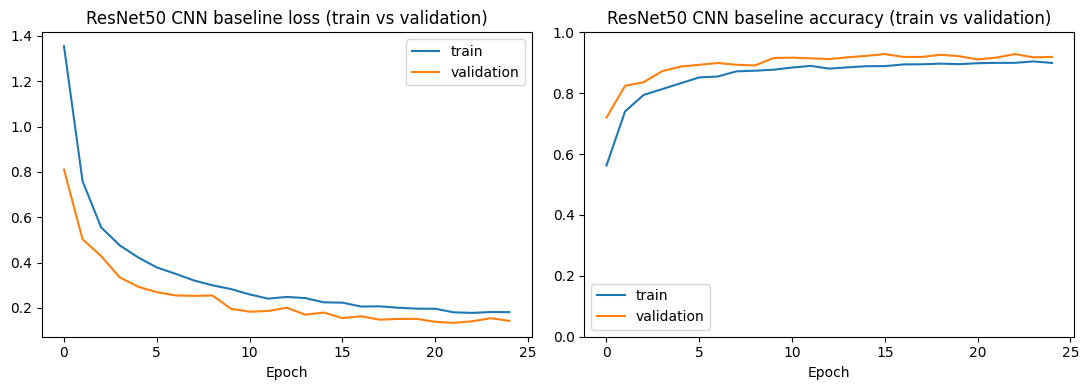


ResNet50 CNN baseline
Overall report accuracy: 0.7610
Training time: 3282.64 seconds
Testing time: 58.00 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.4500 | precision 0.6923 | recall 0.4500 | F1 0.5455 | support 20
Diabetic Retinopathy                                    | acc 0.9272 | precision 0.9180 | recall 0.9272 | F1 0.9226 | support 302
Disc Edema                                              | acc 0.9200 | precision 0.8846 | recall 0.9200 | F1 0.9020 | support 25
Glaucoma                                                | acc 0.7222 | precision 0.6500 | recall 0.7222 | F1 0.6842 | support 270
Healthy                                                 | acc 0.6976 | precision 0.7186 | recall 0.6976 | F1 0.7079 | support 205
Macular Scar                                            | acc 0.6404 | precision 0.7403 | recall 0.6404 | F1 0.6867 | support 89
Myopia                                                  |

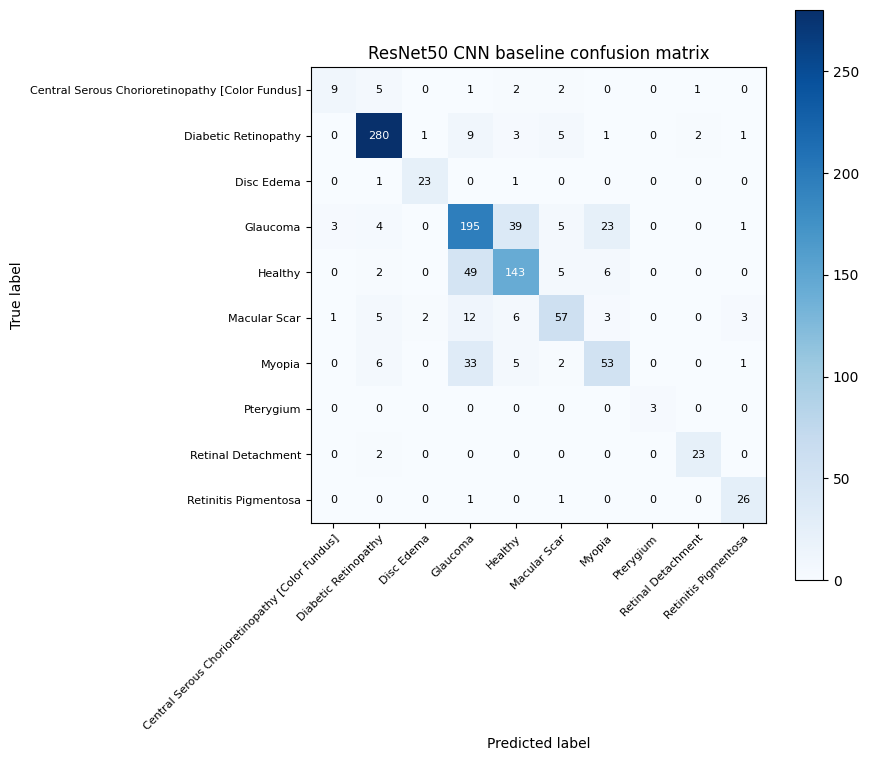

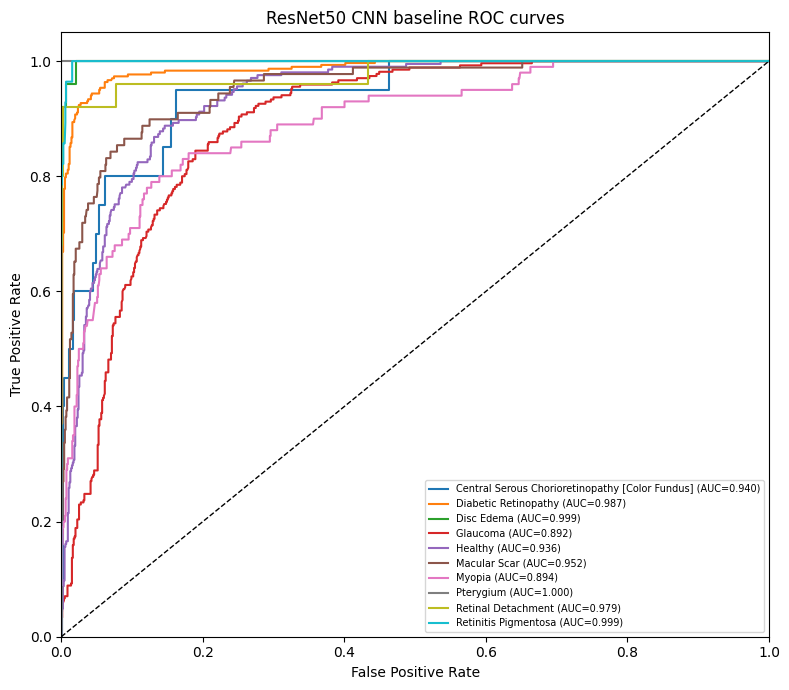

Macro AUC (one-vs-rest): 0.9578


In [16]:
# CNN baseline evaluation
cnn_summary = display_full_evaluation(
    "ResNet50 CNN baseline",
    cnn_y_true,
    cnn_y_pred,
    cnn_y_prob,
    history=cnn_history,
    train_time=cnn_train_time,
    test_time=cnn_test_time,
)

# cell 16

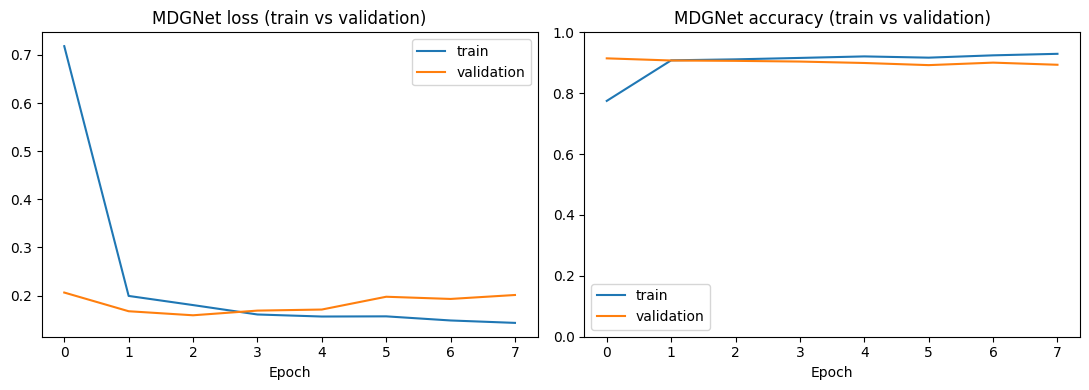


MDGNet
Overall report accuracy: 0.7676
Training time: 6.96 seconds
Testing time: 0.18 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.4000 | precision 0.6667 | recall 0.4000 | F1 0.5000 | support 20
Diabetic Retinopathy                                    | acc 0.9272 | precision 0.9211 | recall 0.9272 | F1 0.9241 | support 302
Disc Edema                                              | acc 0.9200 | precision 0.9583 | recall 0.9200 | F1 0.9388 | support 25
Glaucoma                                                | acc 0.7074 | precision 0.6821 | recall 0.7074 | F1 0.6945 | support 270
Healthy                                                 | acc 0.7463 | precision 0.7150 | recall 0.7463 | F1 0.7303 | support 205
Macular Scar                                            | acc 0.6854 | precision 0.6854 | recall 0.6854 | F1 0.6854 | support 89
Myopia                                                  | acc 0.5400 | preci

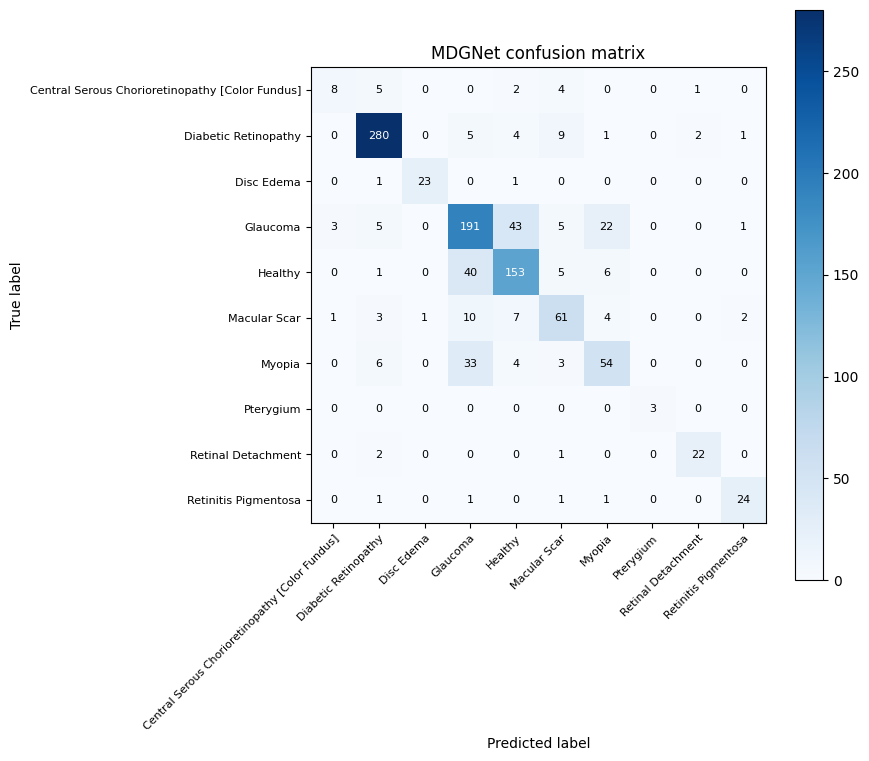

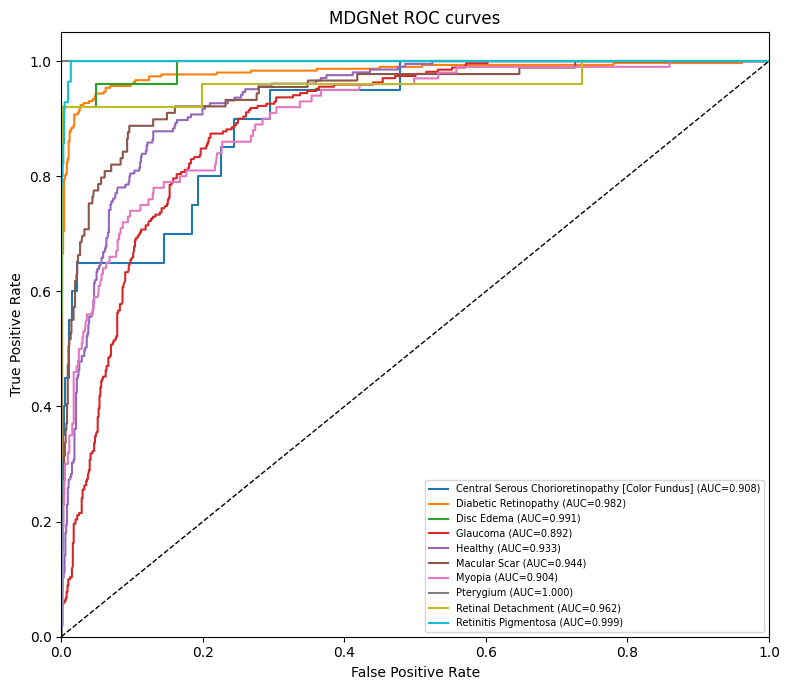

Macro AUC (one-vs-rest): 0.9516


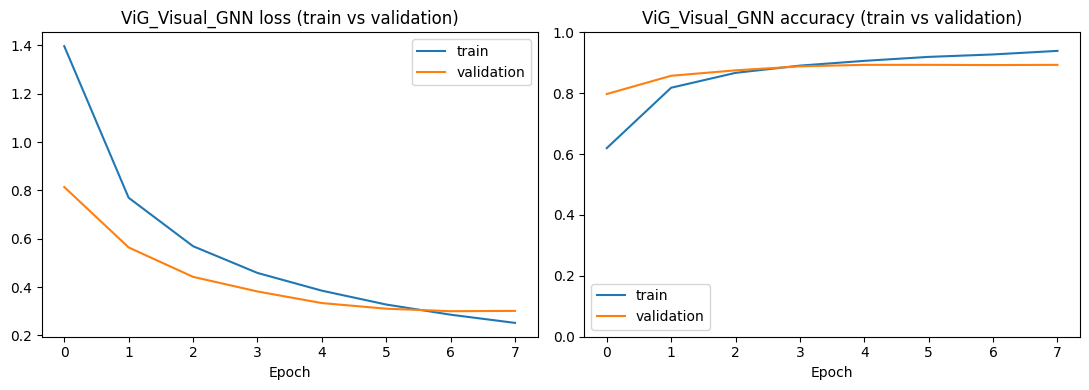


ViG_Visual_GNN
Overall report accuracy: 0.7507
Training time: 58.34 seconds
Testing time: 0.58 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.3000 | precision 0.7500 | recall 0.3000 | F1 0.4286 | support 20
Diabetic Retinopathy                                    | acc 0.9437 | precision 0.9135 | recall 0.9437 | F1 0.9283 | support 302
Disc Edema                                              | acc 0.8400 | precision 0.9545 | recall 0.8400 | F1 0.8936 | support 25
Glaucoma                                                | acc 0.6778 | precision 0.6583 | recall 0.6778 | F1 0.6679 | support 270
Healthy                                                 | acc 0.6976 | precision 0.7079 | recall 0.6976 | F1 0.7027 | support 205
Macular Scar                                            | acc 0.6517 | precision 0.6988 | recall 0.6517 | F1 0.6744 | support 89
Myopia                                                  | acc 0.570

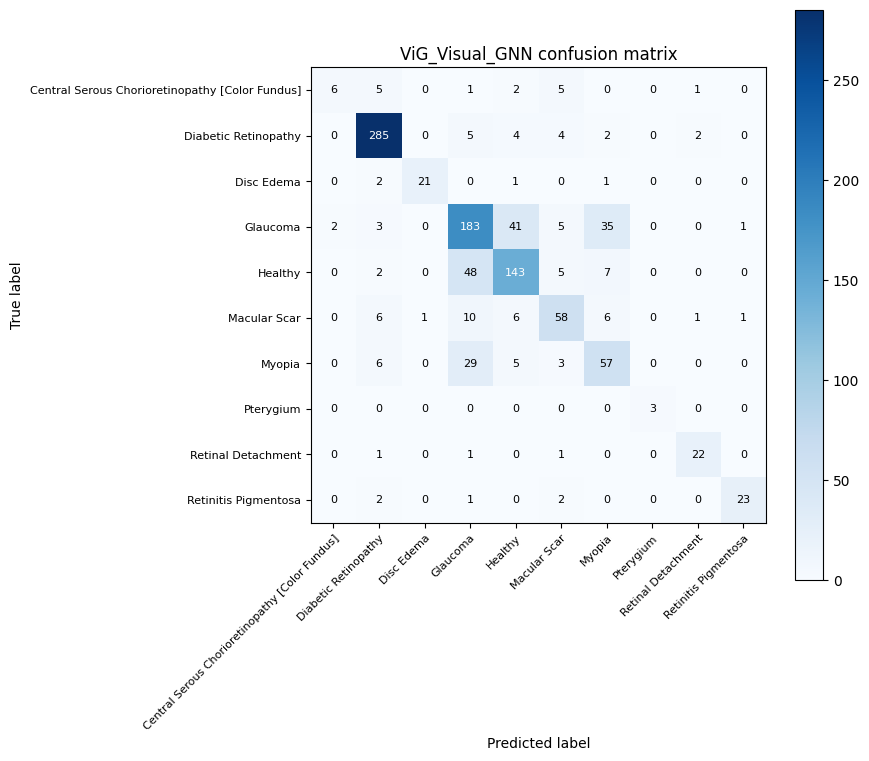

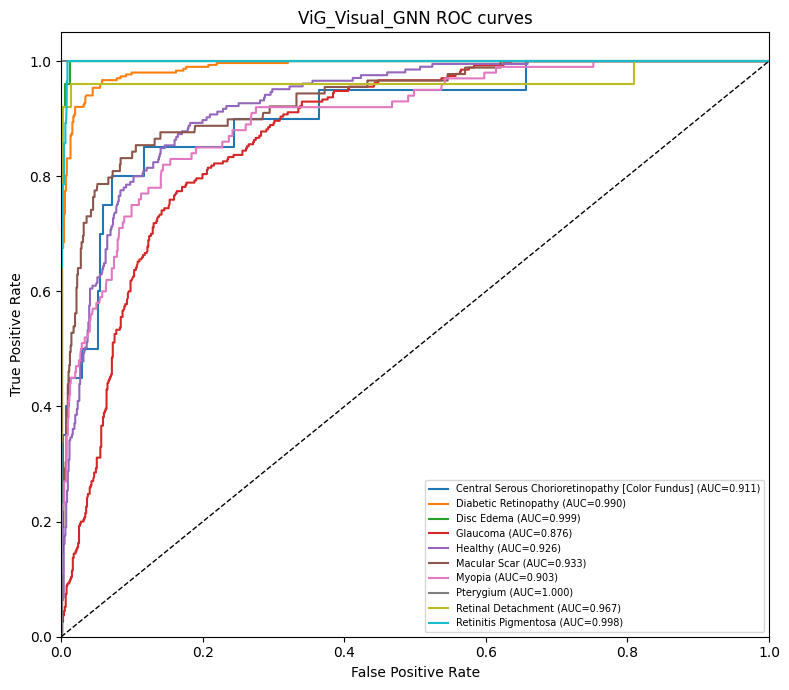

Macro AUC (one-vs-rest): 0.9505


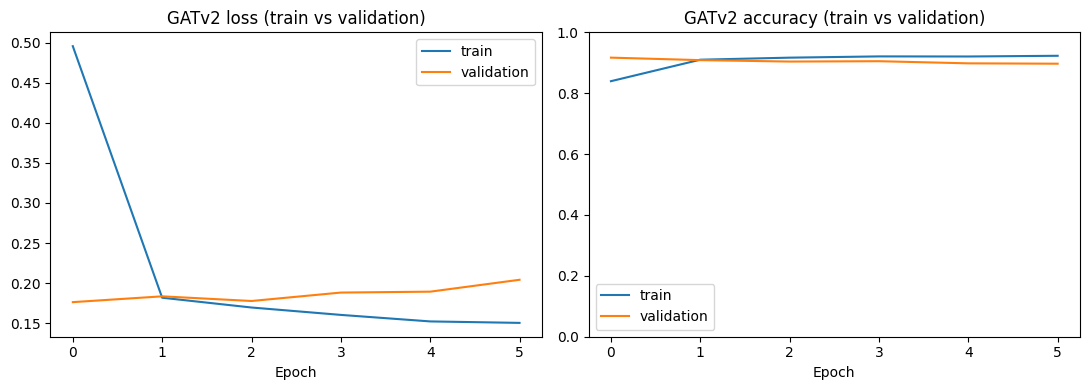


GATv2
Overall report accuracy: 0.7526
Training time: 11.34 seconds
Testing time: 0.31 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.4000 | precision 0.5714 | recall 0.4000 | F1 0.4706 | support 20
Diabetic Retinopathy                                    | acc 0.9172 | precision 0.9295 | recall 0.9172 | F1 0.9233 | support 302
Disc Edema                                              | acc 0.9200 | precision 0.8846 | recall 0.9200 | F1 0.9020 | support 25
Glaucoma                                                | acc 0.7000 | precision 0.6495 | recall 0.7000 | F1 0.6738 | support 270
Healthy                                                 | acc 0.7122 | precision 0.7300 | recall 0.7122 | F1 0.7210 | support 205
Macular Scar                                            | acc 0.6180 | precision 0.7143 | recall 0.6180 | F1 0.6627 | support 89
Myopia                                                  | acc 0.5800 | preci

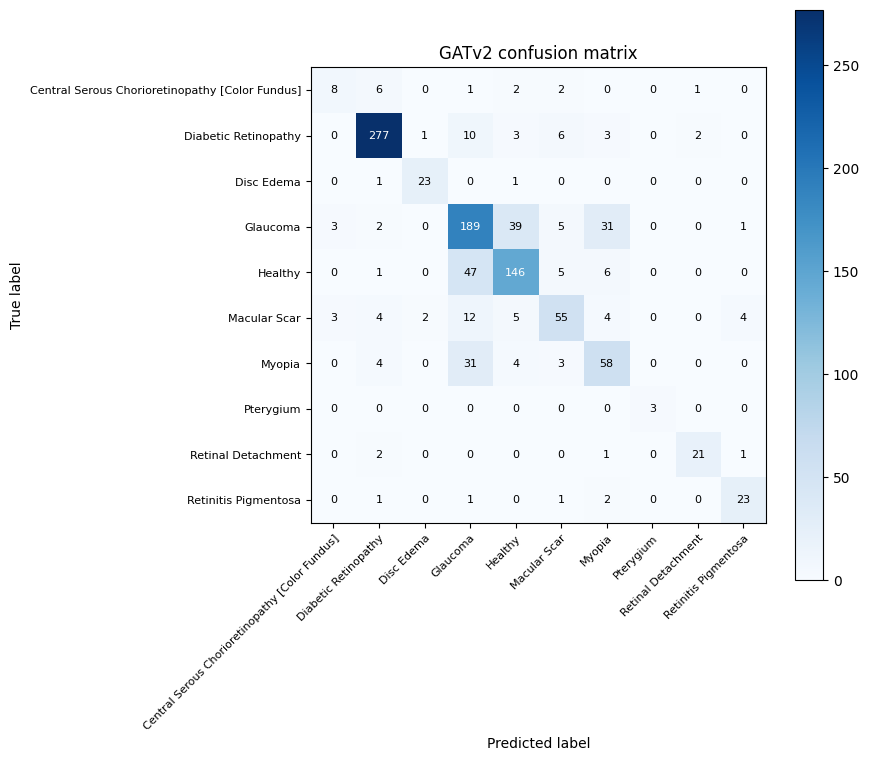

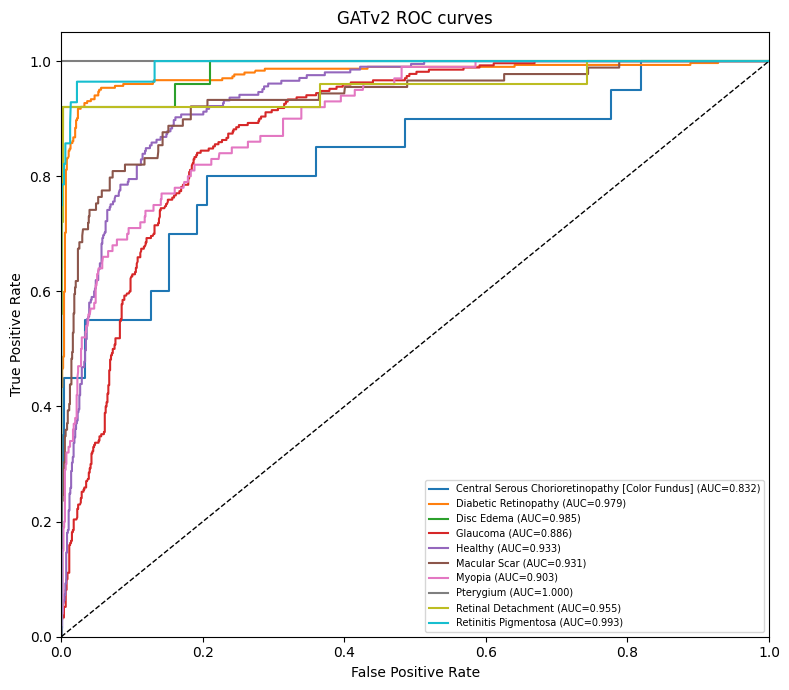

Macro AUC (one-vs-rest): 0.9397


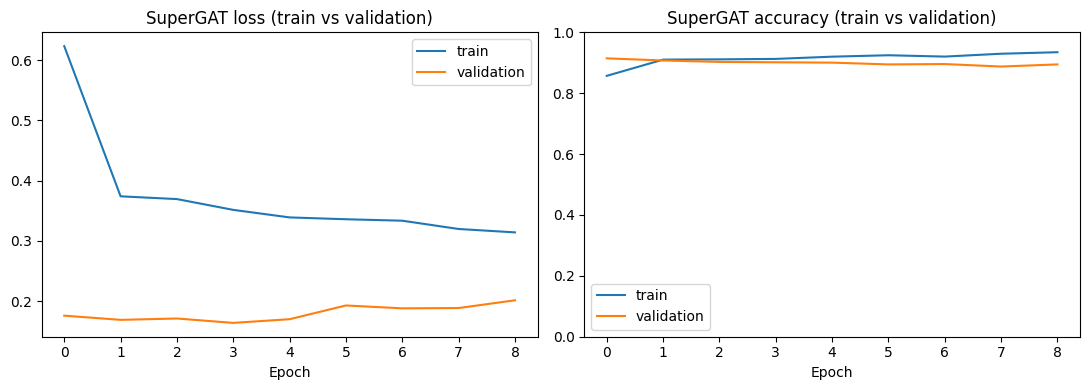


SuperGAT
Overall report accuracy: 0.7648
Training time: 14.10 seconds
Testing time: 0.26 seconds

Per-class accuracy / precision / recall / F1-score
Central Serous Chorioretinopathy [Color Fundus]         | acc 0.4000 | precision 0.7273 | recall 0.4000 | F1 0.5161 | support 20
Diabetic Retinopathy                                    | acc 0.9172 | precision 0.9203 | recall 0.9172 | F1 0.9187 | support 302
Disc Edema                                              | acc 0.9200 | precision 0.9200 | recall 0.9200 | F1 0.9200 | support 25
Glaucoma                                                | acc 0.7185 | precision 0.6644 | recall 0.7185 | F1 0.6904 | support 270
Healthy                                                 | acc 0.7366 | precision 0.7225 | recall 0.7366 | F1 0.7295 | support 205
Macular Scar                                            | acc 0.6742 | precision 0.7317 | recall 0.6742 | F1 0.7018 | support 89
Myopia                                                  | acc 0.5500 | pr

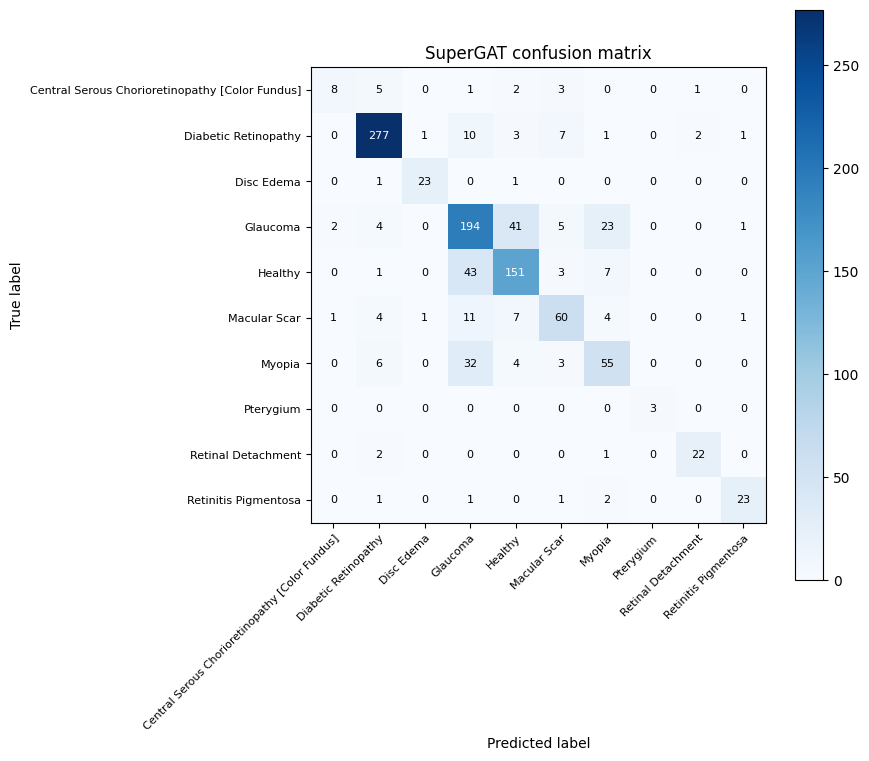

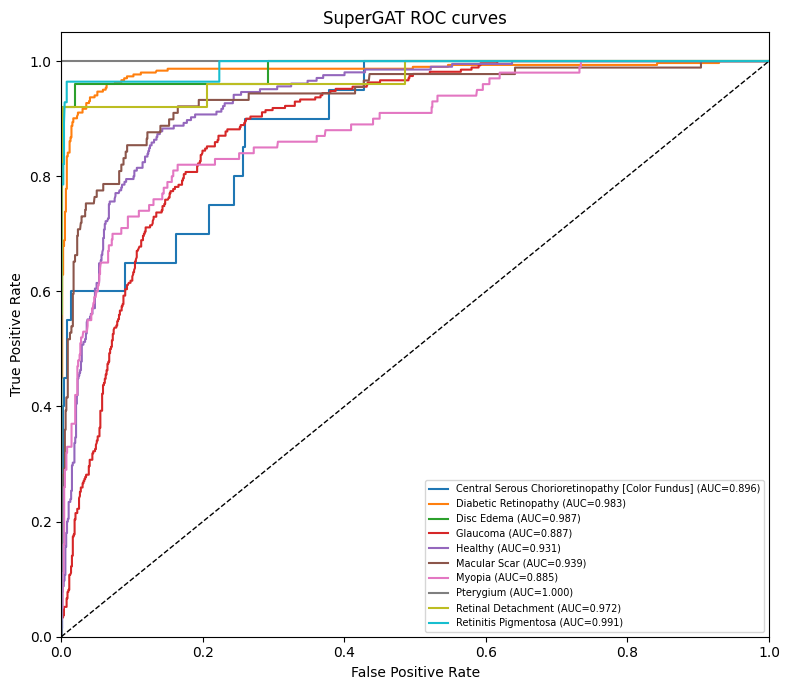

Macro AUC (one-vs-rest): 0.9471


In [17]:
# GNN evaluations
all_model_summaries = {"ResNet50 CNN baseline": cnn_summary}

for name, result in gnn_results.items():
    summary = display_full_evaluation(
        name,
        result["y_true"],
        result["y_pred"],
        result["y_prob"],
        history=result["history"],
        train_time=result["train_time"],
        test_time=result["test_time"],
    )
    all_model_summaries[name] = summary

# cell 17

In [18]:
print("Final summary")
print("=" * 80)
for name, s in all_model_summaries.items():
    print(
        f"{name:25s} | "
        f"accuracy {s['accuracy']:.4f} | "
        f"macro AUC {s['macro_auc']:.4f} | "
        f"train time {s['train_time']:.2f}s | "
        f"test time {s['test_time']:.2f}s"
    )

Final summary
ResNet50 CNN baseline     | accuracy 0.7610 | macro AUC 0.9578 | train time 3282.64s | test time 58.00s
MDGNet                    | accuracy 0.7676 | macro AUC 0.9516 | train time 6.96s | test time 0.18s
ViG_Visual_GNN            | accuracy 0.7507 | macro AUC 0.9505 | train time 58.34s | test time 0.58s
GATv2                     | accuracy 0.7526 | macro AUC 0.9397 | train time 11.34s | test time 0.31s
SuperGAT                  | accuracy 0.7648 | macro AUC 0.9471 | train time 14.10s | test time 0.26s


# cell 18

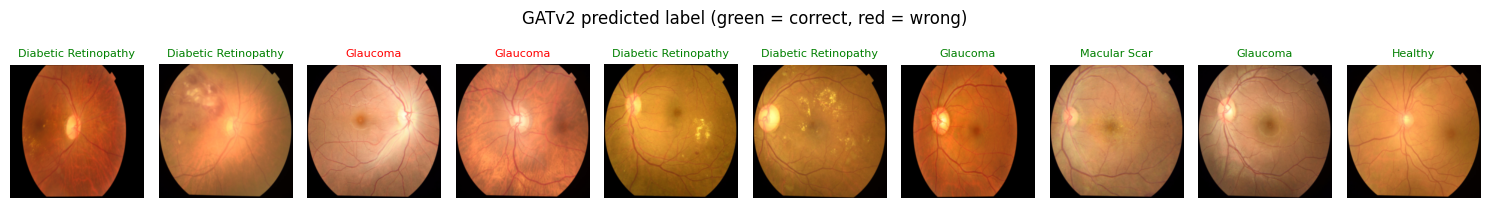

In [19]:
# A few example predictions from the best GNN model.
best_gnn_name = max(gnn_results, key=lambda k: gnn_results[k]["best_val_acc"])
best_model = trained_gnn_models[best_gnn_name]
best_model.eval()

with torch.no_grad():
    logits = best_model(A_hat, X_test[:10].float().to(device))
    preds = logits.argmax(dim=1).cpu().numpy()

fig, axes = plt.subplots(1, min(10, len(display_subset)), figsize=(15, 2.2))
if len(display_subset) == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    img, label = display_subset[i]
    ax.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    correct = preds[i] == y_test[i].item()
    ax.set_title(class_names[preds[i]], color="green" if correct else "red", fontsize=8)
    ax.axis("off")

plt.suptitle(f"{best_gnn_name} predicted label (green = correct, red = wrong)")
plt.tight_layout()
plt.show()